# 06 — Decision Trees

> Classifying by asking a short sequence of yes/no questions, each chosen to leave the groups as pure as possible.

The summary of this lesson is in [README.md](README.md). This notebook is the
full working: the reasoning, the code, and the results.

**Contents**

1. The problem
2. Intuition
3. The mathematics
4. The data
5. Modeling
6. Results and interpretation
7. References

## 1. The problem

A group of patients all had the same illness, and each responded to one of five
drugs: A, B, C, X or Y. For each patient the records hold age, sex, blood
pressure, cholesterol, and the ratio of sodium to potassium in the blood.

The question: given a new patient's measurements, which drug are they likely to
respond to?

It is a multiclass classification problem, like lesson 05 — but this time the
answer should also be **readable**. A doctor will not act on "the 30 most similar
patients voted for drug X". They might act on a rule they can check.

## 2. Intuition

A decision tree is a flowchart learned from data. It asks one question about one
feature — *is the sodium-to-potassium ratio above 14.6?* — and sends each patient
left or right depending on the answer. Each side then asks its own next question,
and so on, until a group is (nearly) all one drug. That group's drug is the
prediction.

Everything depends on **which question to ask first**. A good question separates
the drugs; a useless one leaves both sides as mixed as before. So at every step
the tree tries every feature and every threshold, and keeps the question whose
two resulting groups are the **purest**. Section 3 makes "pure" exact.

Where KNN kept all the training data and compared against it at prediction time,
a tree does all its work up front and then throws the data away: what remains is
a handful of questions.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

# Fixed seed so the train/test split, the cross-validation folds and the tree's
# tie-breaking between equally good splits are identical on every run.
RANDOM_SEED = 3

## 3. The mathematics

**Entropy — how mixed a group is.** For a group of patients where a fraction
$p_c$ responded to drug $c$:

$$
H = -\sum_{c} p_c \log_2 p_c
$$

A group that is all one drug has $H = 0$: there is no uncertainty left. A group
split evenly between two drugs has $H = 1$ bit. Five drugs in equal shares gives
the maximum for this problem, $\log_2 5 \approx 2.32$ bits.

**Information gain — how much a question helps.** A question splits a parent
group of $n$ patients into a left group of $n_L$ and a right group of $n_R$. The
gain is the parent's entropy minus the size-weighted entropy of the children:

$$
\text{IG} = H(\text{parent}) - \left( \frac{n_L}{n} H(\text{left}) + \frac{n_R}{n} H(\text{right}) \right)
$$

Weighting by size matters: a question that peels off two perfectly pure patients
and leaves the other 138 as mixed as before has barely helped.

**Growing the tree — greedy search.** At each node the tree evaluates every
feature and every threshold between adjacent observed values, and keeps the one
with the highest information gain. It then repeats on each child, and stops when
a node is pure or a limit such as `max_depth` is reached. Choices are never
revisited; the tree takes the best question *now* rather than searching for the
best tree overall, which is what makes it fast.

**No distances, so no scaling.** A threshold question on `Na_to_K` does not care
what units `Age` is in. Unlike lesson 05, the features can be used as they are.
They do have to be **numbers**, though — and for categories with a natural order,
the numbers should respect that order, since the tree can only ask "is it at most
this value?".

**No cost function over the whole model.** As with KNN, there is no single
quantity minimised over all parameters at once, as in lessons 01–04. The tree is
built one locally best question at a time.

In [2]:
def entropy(counts):
    # Entropy in bits of a group, given how many members fall in each class.
    p = np.asarray(counts, dtype=float)
    p = p[p > 0] / p.sum()
    # + 0.0 turns the -0.0 of a pure group into a plain 0.0 when printed.
    return -(p * np.log2(p)).sum() + 0.0


print(f"all one drug       [10, 0]:          {entropy([10, 0]):.3f} bits")
print(f"even split         [5, 5]:           {entropy([5, 5]):.3f} bits")
print(f"lopsided           [8, 2]:           {entropy([8, 2]):.3f} bits")
print(f"five drugs, equal  [2, 2, 2, 2, 2]:  {entropy([2, 2, 2, 2, 2]):.3f} bits")

all one drug       [10, 0]:          0.000 bits
even split         [5, 5]:           1.000 bits
lopsided           [8, 2]:           0.722 bits
five drugs, equal  [2, 2, 2, 2, 2]:  2.322 bits


The more mixed the group, the higher the entropy. An 8-to-2 group is not pure,
but it is far less uncertain than a 5-to-5 one.

## 4. The data

Patient records for a drug-response study, 200 rows, as supplied with the course.

In [3]:
df = pd.read_csv("data/drug200.csv")

# take a look at the dataset
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [4]:
print(df.shape)
print("missing values:", df.isna().sum().sum())
print("duplicate rows:", df.duplicated().sum())

(200, 6)
missing values: 0
duplicate rows: 0


200 patients, no missing values, no duplicates.

| Column | Meaning |
|---|---|
| `Age` | Age in years, 15–74 |
| `Sex` | `F` / `M` |
| `BP` | Blood pressure: `LOW`, `NORMAL`, `HIGH` |
| `Cholesterol` | `NORMAL` / `HIGH` |
| `Na_to_K` | Sodium-to-potassium ratio in the blood |
| `Drug` | **Target** — the drug the patient responded to |

In [5]:
df["Drug"].value_counts()

Drug
drugY    91
drugX    54
drugA    23
drugC    16
drugB    16
Name: count, dtype: int64

Far from balanced: drug Y alone accounts for 91 of the 200 patients, and drugs B
and C for only 16 each. Always answering "drug Y" would already be right about
45% of the time — the floor any model has to clear.

Before modelling anything, one plot. `Na_to_K` against age, coloured by drug:

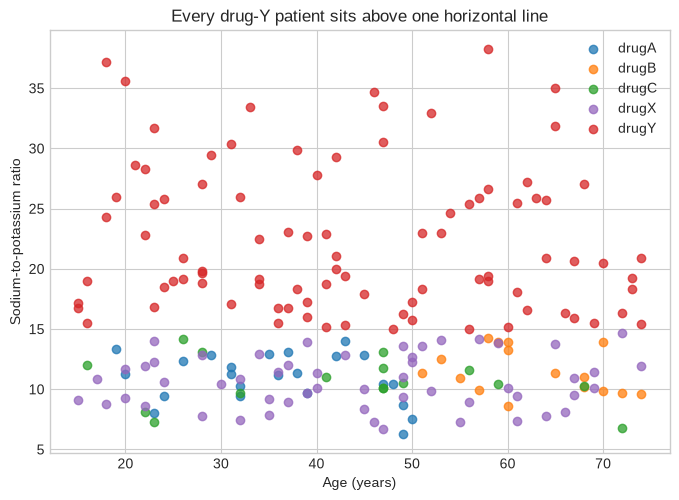

In [6]:
drug_colours = {
    "drugA": "tab:blue",
    "drugB": "tab:orange",
    "drugC": "tab:green",
    "drugX": "tab:purple",
    "drugY": "tab:red",
}

fig, ax = plt.subplots(figsize=(8, 5.5))
for drug, colour in drug_colours.items():
    group = df[df["Drug"] == drug]
    ax.scatter(group["Age"], group["Na_to_K"], color=colour, alpha=0.75, label=drug)

ax.set_xlabel("Age (years)")
ax.set_ylabel("Sodium-to-potassium ratio")
ax.set_title("Every drug-Y patient sits above one horizontal line")
ax.legend()
plt.show()

One question already separates drug Y from everything else: every red point lies
above a ratio of about 15, and every other point below it. That is exactly the
kind of question a tree looks for, and it is a strong hint that this dataset
follows simple rules.

### Encoding the categorical columns

`Sex`, `BP` and `Cholesterol` are text, and the tree needs numbers.

A common shortcut is `LabelEncoder`, but it assigns codes **alphabetically**:
for blood pressure that gives `HIGH` = 0, `LOW` = 1, `NORMAL` = 2, which puts
normal pressure above high pressure. A tree can only ask "is BP at most some
value?", so with that coding it cannot ask "is blood pressure high?" in one
question.

Blood pressure has a real order, so it is mapped by hand to respect it. The two
binary columns get an explicit 0/1 so the tree printout is easy to read.

In [7]:
X = pd.DataFrame(
    {
        "Age": df["Age"],
        "Sex": df["Sex"].map({"F": 0, "M": 1}),
        "BP": df["BP"].map({"LOW": 0, "NORMAL": 1, "HIGH": 2}),
        "Cholesterol": df["Cholesterol"].map({"NORMAL": 0, "HIGH": 1}),
        "Na_to_K": df["Na_to_K"],
    }
)
y = df["Drug"]

X.head()

,Age,Sex,BP,Cholesterol,Na_to_K
0,23,0,2,1,25.355
1,47,1,0,1,13.093
2,47,1,0,1,10.114
3,28,0,1,1,7.798
4,61,0,0,1,18.043


### Creating train and test datasets

70% of patients to build the tree, 30% held back. The test set is used once, at
the end.

In [8]:
from sklearn.model_selection import train_test_split

X_trainset, X_testset, y_trainset, y_testset = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_SEED
)

print("Training set:", X_trainset.shape, y_trainset.shape)
print("Test set:    ", X_testset.shape, y_testset.shape)

Training set: (140, 5) (140,)
Test set:     (60, 5) (60,)


## 5. Modeling

`criterion="entropy"` makes the tree choose its questions by information gain,
as in section 3. `max_depth=4` limits it to at most four questions from root to
leaf.

In [9]:
from sklearn.tree import DecisionTreeClassifier

drugTree = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=RANDOM_SEED)
drugTree.fit(X_trainset, y_trainset)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",3
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

### Checking the first question by hand

The root of the tree is the single most useful question the tree found. The
information gain of that question can be computed from the formulas in section
3 and compared with what scikit-learn reports.

In [10]:
root_feature = X.columns[drugTree.tree_.feature[0]]
root_threshold = drugTree.tree_.threshold[0]

left = y_trainset[X_trainset[root_feature] <= root_threshold]
right = y_trainset[X_trainset[root_feature] > root_threshold]

h_parent = entropy(y_trainset.value_counts())
h_left = entropy(left.value_counts())
h_right = entropy(right.value_counts())
n, n_left, n_right = len(y_trainset), len(left), len(right)
gain = h_parent - (n_left / n * h_left + n_right / n * h_right)

print(f"Root question: {root_feature} <= {root_threshold:.2f}")
print(f"  parent: {n} patients, entropy {h_parent:.3f} bits")
print(f"  left:   {n_left} patients, entropy {h_left:.3f} bits  {left.value_counts().to_dict()}")
print(f"  right:  {n_right} patients, entropy {h_right:.3f} bits  {right.value_counts().to_dict()}")
print(f"  information gain: {gain:.3f} bits")
print()
print(f"scikit-learn's root entropy: {drugTree.tree_.impurity[0]:.3f} bits")

Root question: Na_to_K <= 14.62
  parent: 140 patients, entropy 1.929 bits
  left:   71 patients, entropy 1.832 bits  {'drugX': 33, 'drugA': 16, 'drugC': 11, 'drugB': 11}
  right:  69 patients, entropy 0.000 bits  {'drugY': 69}
  information gain: 1.000 bits

scikit-learn's root entropy: 1.929 bits


The hand calculation matches scikit-learn's. The first question sends every
drug-Y patient right, into a group of entropy 0, and leaves the other four drugs
on the left for later questions to sort out.

Why that question and not another? The same calculation for the best threshold
on each feature:

In [11]:
def best_split(feature):
    # The threshold on one feature with the highest information gain.
    values = np.sort(X_trainset[feature].unique())
    thresholds = (values[:-1] + values[1:]) / 2
    best = (None, -1.0)
    for t in thresholds:
        l = y_trainset[X_trainset[feature] <= t]
        r = y_trainset[X_trainset[feature] > t]
        g = h_parent - (len(l) / n * entropy(l.value_counts()) + len(r) / n * entropy(r.value_counts()))
        if g > best[1]:
            best = (t, g)
    return best


pd.DataFrame(
    [(f, *best_split(f)) for f in X.columns],
    columns=["feature", "best threshold", "information gain (bits)"],
).set_index("feature").sort_values("information gain (bits)", ascending=False).round(3)

,best threshold,information gain (bits)
feature,,
Na_to_K,14.616,1.000
BP,1.500,0.488
Age,50.500,0.200
Cholesterol,0.500,0.108
Sex,0.500,0.014


`Na_to_K` wins by a wide margin. Blood pressure is a distant second, and sex
carries almost no information about which drug a patient responded to.

### The whole tree

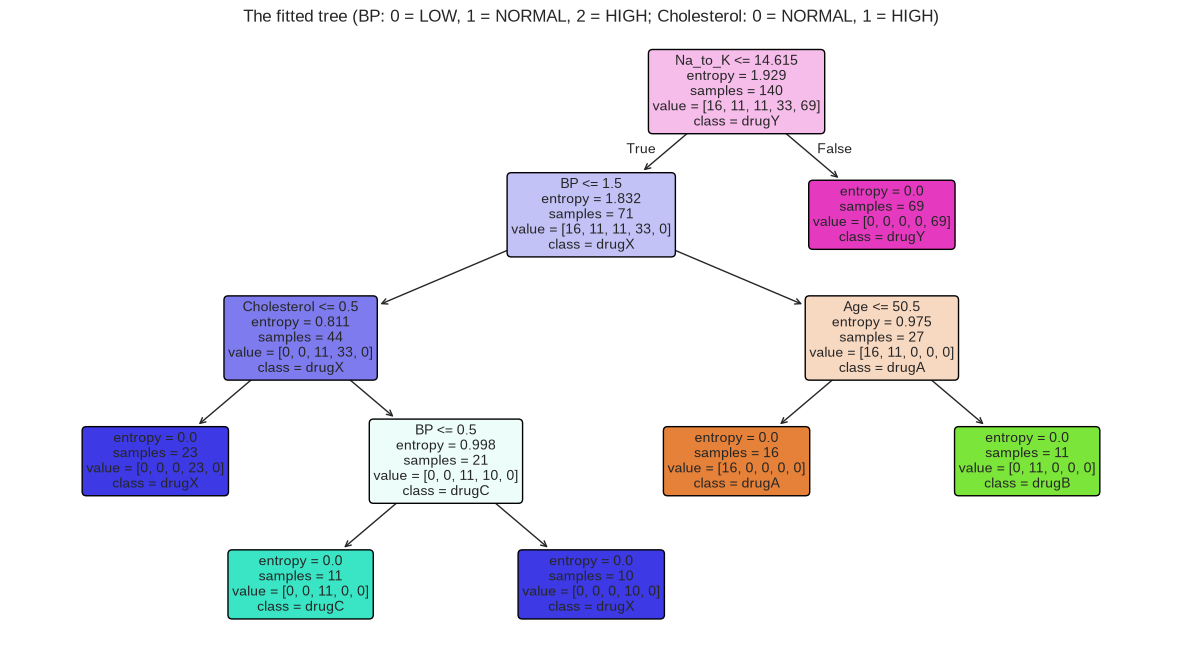

In [12]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(15, 8))
plot_tree(
    drugTree,
    feature_names=list(X.columns),
    class_names=list(drugTree.classes_),
    filled=True,
    rounded=True,
    impurity=True,
    fontsize=10,
    ax=ax,
)
ax.set_title("The fitted tree (BP: 0 = LOW, 1 = NORMAL, 2 = HIGH; Cholesterol: 0 = NORMAL, 1 = HIGH)")

# Saved so README.md can show the result without anyone running this notebook.
plt.savefig("figures/result.png", dpi=150, bbox_inches="tight")
plt.show()

Each box shows the question asked, the node's entropy, how many training
patients reached it, how they divide between the five drugs, and the majority
drug. The same tree as plain text:

In [13]:
from sklearn.tree import export_text

print(export_text(drugTree, feature_names=list(X.columns)))

|--- Na_to_K <= 14.62
|   |--- BP <= 1.50
|   |   |--- Cholesterol <= 0.50
|   |   |   |--- class: drugX
|   |   |--- Cholesterol >  0.50
|   |   |   |--- BP <= 0.50
|   |   |   |   |--- class: drugC
|   |   |   |--- BP >  0.50
|   |   |   |   |--- class: drugX
|   |--- BP >  1.50
|   |   |--- Age <= 50.50
|   |   |   |--- class: drugA
|   |   |--- Age >  50.50
|   |   |   |--- class: drugB
|--- Na_to_K >  14.62
|   |--- class: drugY



Read from the top, the tree is a complete prescribing rule:

1. **Na_to_K above ~14.6** → drug Y.
2. Otherwise, **high blood pressure** → drug A if aged 50 or under, drug B if older.
3. Otherwise, **low blood pressure with high cholesterol** → drug C.
4. Everyone else → drug X.

Every leaf has entropy 0: each final group in the training data is a single drug.
`Sex` never appears — consistent with its near-zero information gain above.

## 6. Results and interpretation

### Prediction and accuracy

In [14]:
predTree = drugTree.predict(X_testset)

print("predicted:", list(predTree[0:5]))
print("actual:   ", list(y_testset[0:5]))

predicted: ['drugY', 'drugX', 'drugX', 'drugX', 'drugX']
actual:    ['drugY', 'drugX', 'drugX', 'drugX', 'drugX']


In [15]:
from sklearn import metrics
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent").fit(X_trainset, y_trainset)
baseline_acc = metrics.accuracy_score(y_testset, baseline.predict(X_testset))
tree_acc = metrics.accuracy_score(y_testset, predTree)

print(f"Always predict {baseline.predict(X_testset[:1])[0]}:  test accuracy {baseline_acc:.4f}")
print(f"Decision tree:          test accuracy {tree_acc:.4f}")

Always predict drugY:  test accuracy 0.3667
Decision tree:          test accuracy 0.9833


### Is depth 4 the right limit?

`max_depth` is a hyperparameter, set by hand. As in lesson 05 it is compared by
5-fold cross-validation on the training set, never on the test set. The test
column is shown for comparison only.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

rows = []
for depth in [1, 2, 3, 4, 5, None]:
    tree_d = DecisionTreeClassifier(criterion="entropy", max_depth=depth, random_state=RANDOM_SEED)
    cv_scores = cross_val_score(tree_d, X_trainset, y_trainset, cv=cv)
    tree_d.fit(X_trainset, y_trainset)
    rows.append(
        {
            "max_depth": "none" if depth is None else depth,
            "actual depth": tree_d.get_depth(),
            "leaves": tree_d.get_n_leaves(),
            "train": metrics.accuracy_score(y_trainset, tree_d.predict(X_trainset)),
            "cv mean": cv_scores.mean(),
            "test (not used to choose)": metrics.accuracy_score(y_testset, tree_d.predict(X_testset)),
        }
    )

pd.DataFrame(rows).set_index("max_depth").round(4)

,actual depth,leaves,train,cv mean,test (not used to choose)
max_depth,,,,,
1,1,2,0.7286,0.7286,0.7000
2,2,3,0.8429,0.8429,0.8167
3,3,5,0.9286,0.9071,0.8167
4,4,6,1.0000,0.9929,0.9833
5,4,6,1.0000,0.9929,0.9833
none,4,6,1.0000,0.9929,0.9833


Cross-validated accuracy climbs with every extra level up to 4 and then stops
moving. The *actual depth* column shows why: with no limit at all, the tree still
stops at depth 4, because by then every leaf is pure and there is nothing left to
split. `max_depth=4` was never constraining this tree — it is simply how deep
these rules are.

### Where it fails

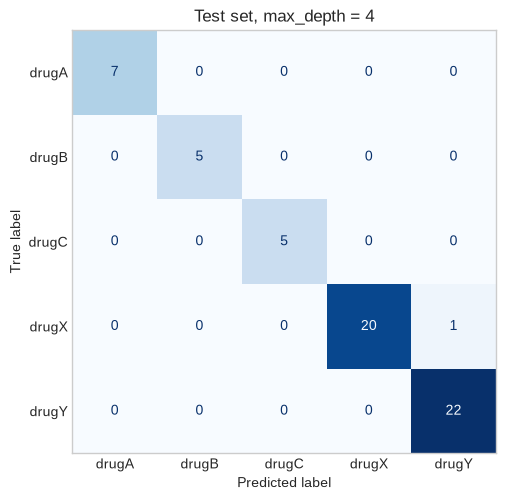

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_testset, predTree, labels=drugTree.classes_, cmap="Blues", colorbar=False, ax=ax
)
ax.grid(False)
ax.set_title("Test set, max_depth = 4")
plt.show()

In [18]:
wrong = X_testset[predTree != y_testset].copy()
wrong["actual"] = y_testset[predTree != y_testset]
wrong["predicted"] = predTree[predTree != y_testset]
wrong

,Age,Sex,BP,Cholesterol,Na_to_K,actual,predicted
153,72,0,0,0,14.642,drugX,drugY


In [19]:
print(f"Tree's threshold:                        Na_to_K <= {root_threshold:.3f}")
print(f"Highest Na_to_K of any non-Y patient:    {df.loc[df['Drug'] != 'drugY', 'Na_to_K'].max():.3f}")
print(f"Lowest Na_to_K of any drug-Y patient:    {df.loc[df['Drug'] == 'drugY', 'Na_to_K'].min():.3f}")

Tree's threshold:                        Na_to_K <= 14.615
Highest Na_to_K of any non-Y patient:    14.642
Lowest Na_to_K of any drug-Y patient:    15.015


### Reading the result

One mistake in 60 test patients: **0.983 accuracy**, against 0.367 for always
answering drug Y. Cross-validation on the training set agrees (0.993), so this is
not a lucky split.

**The one error is instructive.** The misclassified patient has a
sodium-to-potassium ratio of 14.642 and responded to drug X. Across the whole
dataset, the highest ratio of any non-Y patient is 14.642 — this one — and the
lowest ratio of any drug-Y patient is 15.015. The true boundary lies somewhere in
that gap. But this patient was in the test set, so the tree never saw them; the
closest non-Y ratio in its training data was lower, and it placed its threshold
halfway between the values it had, at 14.615. The patient sits about 0.03 above
that line and was sent to drug Y.

That is how every tree threshold works: it is the midpoint between two observed
training values, and the model has no way of knowing where in an empty gap the
real boundary lies. With 140 training patients, some gaps are bound to be wide.

**Why the accuracy is so high — and what it does not mean.** The printed tree
is not an approximation of the data; it is a complete description of it. Four
simple rules reproduce every one of the 200 drug labels. Real clinical data is
never that clean: this dataset was evidently generated from rules like these for
teaching. So 98% here says that the tree **recovered the rules that generated
the data**, which is a real demonstration of the method — not that drug response
is easy to predict, and certainly not a basis for prescribing anything.

**Compared with lesson 05.** KNN on the customer data could only say "these
customers resemble those ones", and weighted all eleven features equally. The
tree here tells you exactly which features matter (`Na_to_K`, `BP`, `Age`,
`Cholesterol`), which one does not (`Sex`), and in what order to ask. That
readability is the main reason to reach for a tree.

**The weakness to carry forward.** A tree grown until its leaves are pure fits
its training data perfectly — and on noisy data, "perfectly" means memorising
noise. Here there was no noise to memorise, so the unconstrained tree was
harmless. On messier data, depth has to be limited, and a single tree changes a
lot when a few training rows change. Ensembles of many trees, such as random
forests, exist to fix exactly that.

## 7. References

- Course: Machine Learning with Python (Jadi) — lesson on decision trees, which
  uses this dataset and framing.
- Dataset: `drug200.csv`, patient drug-response records, as supplied with the
  course.
- scikit-learn documentation: [Decision Trees](https://scikit-learn.org/stable/modules/tree.html)
- scikit-learn documentation: [`sklearn.tree.plot_tree`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html)